In [1]:
from google.colab import files
files.upload()
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


In [28]:
import kagglehub
import shutil

# Download latest version
path = kagglehub.dataset_download("patelris/crop-yield-prediction-dataset")
destination = "/content/crop-yield-prediction-dataset"
shutil.copytree(path, destination, dirs_exist_ok=True)

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'crop-yield-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/crop-yield-prediction-dataset


In [ ]:
# demo cell
w=b=0.0; lr=0.01
for e in range(500):
    err=w*x+b-y
    w-=lr*2*(err*x).mean(); b-=lr*2*err.mean()
    loss=(err**2).mean()   # store and plot

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("/content/crop-yield-prediction-dataset/yield_df.csv")
df = pd.DataFrame(data)

In [ ]:
yield_crops = df['hg/ha_yield'].to_numpy()
rainfall = df['average_rain_fall_mm_per_year'].to_numpy()

idx=np.random.default_rng(0).permutation(len(yield_crops))
cut=int(0.8*len(yield_crops)); tr,te=idx[:cut],idx[cut:]



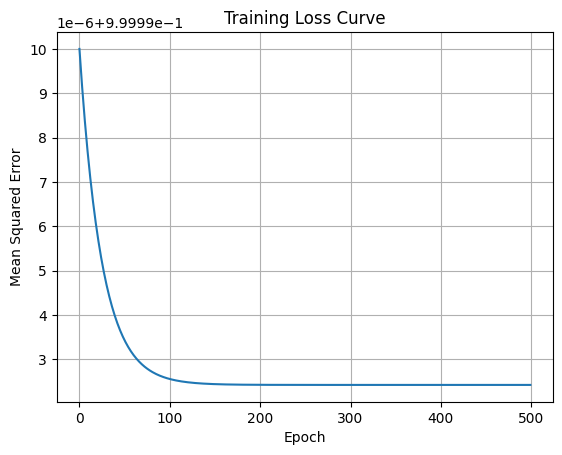

Final Training MSE: 0.9999924199728734
Test MSE: 7405769642.830125
Test RMSE: 86056.78150401701


In [39]:
#select training data
x = rainfall[tr]
y = yield_crops[tr]

#standardise training data
x_mean, x_std = x.mean(), x.std()
y_mean, y_std = y.mean(), y.std()

x = (x - x_mean) / x_std
y = (y - y_mean) / y_std

#initialise parameters
w=b= 0.0
lr= 0.01
loss_history = []

# Train the model
for e in range(500):
    err = w*x + b - y
    w -= lr * 2 * (err*x).mean()
    b -= lr * 2 * err.mean()
    loss = (err**2).mean()
    loss_history.append(loss)

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training Loss Curve")
plt.grid(True)
plt.show()

#calculate final training MSE
train_pred_scaled = w*x + b
train_mse_scaled = ((y - train_pred_scaled)**2).mean()

#calculate test predictions
x_test = (rainfall[te] - x_mean) / x_std
y_pred_scaled = w*x_test + b

#convert predictions back to original crop yield scale
y_pred = y_pred_scaled * y_std + y_mean
y_actual = yield_crops[te]

#calculate test MSE and RMSE
test_mse = ((y_actual - y_pred)**2).mean()
test_rmse = np.sqrt(test_mse)

print("Final Training MSE:", train_mse_scaled)
print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)